# Oxford-IIIT Pet — Multi-task CNN Pipeline

> **NO-AUGMENTATION VARIANT** — identical to the original notebook (same model, data pipeline,
> training and evaluation); every form of data augmentation is disabled:
> train-time transforms (flip / affine / RandAugment / cutout), MixUp, and test-time augmentation.
**Segmentation (Attention U-Net)** + **Breed Classification (37 classes)** trained together.

## Requirements covered
| Requirement | Where |
|---|---|
| **Attention U-Net** architecture ([arXiv:1804.03999](https://arxiv.org/abs/1804.03999)) - Attention Gates on all 4 skips | Model section |
| Classifier head attached to the **encoder output**, trained jointly | Model section |
| Result summaries: **mIoU, Dice coefficient, pixel accuracy** (segmentation) and **accuracy, precision, recall, F1** (classification) for **train / validation / test** | *Result Summary* section |
| Prediction viewer that takes **any image index**: `[original image] [image + true overlay] [image + predicted mask overlay]`, `original class -`, `predict class -`, `iou -` | *Prediction Viewer* section |
| Common preprocessing pipeline (**no augmentation**) | Dataset section |

## Kaggle setup
1. Notebook settings → **Accelerator: GPU (T4 / P100)**.
2. **Add Input** → search *"Oxford-IIIT-Pet"* and attach a dataset containing `images/` and `annotations/trimaps/`.
   (If no local dataset is attached, the notebook falls back to a `torchvision` download — enable **Internet** for that.)
3. Run all cells. Expected runtime: ~2.5 h on a T4 (224 px, 55 epochs).

> **Mask preprocessing (required step):** raw trimap values are **1 = foreground**, **2 = background**, **3 = boundary / unclassified**.
> We load the data and convert **{1, 3} → foreground (pet)**, keeping {2} as background — i.e. *boundary/unclassified pixels become foreground*.
> Implemented in `OxfordPetMultiTask.load_mask` via `np.isin(m, [1, 3])`. Set `CFG.BINARY_SEG = False` for 3-class mode instead.

In [1]:
import os
from pathlib import Path

class CFG:
    IMG_SIZE     = 224     # 224 px: fine-grained breeds need resolution
    BATCH_SIZE   = 20      # fits T4 16GB with AMP at 224 px + larger model
    EPOCHS       = 55      # full convergence at 224 px
    LR           = 3e-4
    WEIGHT_DECAY = 3e-4     # stronger L2 penalty vs overfitting
    NUM_CLASSES  = 37
    BINARY_SEG   = True      # True: {1,3}->pet, {2}->background ; False: 3-class trimap
    VAL_SPLIT    = 0.15      # stratified validation split out of trainval.txt
    SEED         = 42
    PATIENCE     = 10        # early-stopping patience on val mIoU
    BASE_CH      = 80        # U-Net base channel width (64→80: richer features for 37 breeds)
    AMP          = True      # mixed precision (GPU only)
    LABEL_SMOOTH = 0.10      # softer targets curb memorization
    CLS_DROPOUT  = 0.50      # classifier-head dropout
    ERASE_P      = 0.0       # cutout (RandomErasing) DISABLED - no augmentation
    NUM_WORKERS  = 0         # in-process loading -> no worker-shutdown traceback spam
    MIXUP_ALPHA  = 0.0       # MixUp DISABLED - no augmentation
    MIXUP_PROB   = 0.0       # fraction of train batches mixed (inactive)
    USE_TTA      = False     # test-time augmentation DISABLED (no augmentation)
    RANDAUG_N    = 0         # RandAugment DISABLED - no augmentation
    RANDAUG_M    = 0         # RandAugment magnitude (inactive)

SEG_CLASSES     = 2 if CFG.BINARY_SEG else 3
SEG_CLASS_NAMES = ["background", "pet"] if CFG.BINARY_SEG else ["foreground", "background", "outline"]
OUT_DIR         = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
print("Output dir:", OUT_DIR.resolve())

Output dir: /kaggle/working


In [2]:
import os, re, random, time, copy, json, math, warnings
from collections import Counter

os.environ["PYTHONWARNINGS"] = "ignore"   # hide warnings raised inside subprocesses
warnings.filterwarnings("ignore")         # hide ALL python warnings (deprecations etc.)
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
import torchvision.transforms.functional as TF
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

try:
    from tqdm import tqdm        # plain text bars (no ipywidgets -> no 'model not found' errors)
except Exception:
    def tqdm(x, **kwargs):
        return x

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(CFG.SEED)
DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = bool(CFG.AMP and DEVICE.type == "cuda")
print("torch :", torch.__version__)
print("device:", DEVICE, "| AMP:", USE_AMP)
if DEVICE.type == "cuda":
    cap  = torch.cuda.get_device_capability(0)
    arch = torch.cuda.get_arch_list()
    print("GPU   :", torch.cuda.get_device_name(0), f"| compute capability: sm_{cap[0]}{cap[1]}")
    print("torch compiled CUDA kernels for:", arch)
    if f"sm_{cap[0]}{cap[1]}" not in arch and not any(a.startswith("compute_") for a in arch):
        raise RuntimeError(
            f"torch {torch.__version__} (built for CUDA {torch.version.cuda}) ships no GPU kernels for "
            f"sm_{cap[0]}{cap[1]} ({torch.cuda.get_device_name(0)}), so the first CUDA op fails with "
            "'no kernel image is available for execution on the device'.\n"
            "FIX: Kaggle Settings -> Accelerator -> select 'GPU T4 x2' or 'GPU P100' "
            "(supported by this torch build), then Restart & Run All.\n"
            "Advanced (needs Internet): install a torch build that matches this GPU, e.g. "
            "pip install --upgrade torch --index-url https://download.pytorch.org/whl/cu128"
        )

torch : 2.10.0+cu128
device: cuda | AMP: True
GPU   : Tesla T4 | compute capability: sm_75
torch compiled CUDA kernels for: ['sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90', 'sm_100', 'sm_120']


In [3]:
def _find_images_dir(base):
    for cand in sorted(base.rglob("*")):
        if cand.is_dir() and cand.name.lower() in ("images", "jpg", "imgs"):
            if any(cand.glob("*.jpg")):
                return cand
    return None

def locate_dataset():
    root = Path("/kaggle/input")
    if root.exists():
        for trim in root.rglob("trimaps"):
            ann = trim.parent
            imgs = _find_images_dir(ann.parent) or _find_images_dir(ann)
            if imgs is not None:
                return imgs, ann
    return None, None

IMAGES_DIR, ANN_DIR = locate_dataset()

if IMAGES_DIR is None:
    print("Dataset not found in /kaggle/input -> falling back to torchvision download (Internet required).")
    from torchvision.datasets import OxfordIIITPet
    dl_root = Path("/kaggle/working/pet_data") if Path("/kaggle/working").exists() else Path("./pet_data")
    dl_root.mkdir(parents=True, exist_ok=True)
    OxfordIIITPet(root=str(dl_root), download=True)
    base = dl_root / "oxford-iiit-pet"
    IMAGES_DIR, ANN_DIR = base / "images", base / "annotations"

TRIMAPS_DIR = ANN_DIR / "trimaps"
assert TRIMAPS_DIR.exists(), f"trimaps folder not found under {ANN_DIR}"
print("images  :", IMAGES_DIR)
print("trimaps :", TRIMAPS_DIR)

def read_split(txt_path):
    entries = []
    with open(txt_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = line.split()
            entries.append((parts[0], int(parts[1])))
    return entries

trainval_txt, test_txt, list_txt = ANN_DIR / "trainval.txt", ANN_DIR / "test.txt", ANN_DIR / "list.txt"

if trainval_txt.exists() and test_txt.exists():
    trainval_entries = read_split(trainval_txt)
    test_entries     = read_split(test_txt)
elif list_txt.exists():
    all_entries      = read_split(list_txt)
    trainval_entries, test_entries = train_test_split(
        all_entries, test_size=0.5, stratify=[c for _, c in all_entries], random_state=CFG.SEED)
else:
    raise FileNotFoundError("Need trainval.txt / test.txt (or list.txt) inside the annotations folder.")

def breed_of(stem):
    return re.sub(r"_\d+$", "", stem)

id2name = {}
for s, c in trainval_entries + test_entries:
    id2name.setdefault(c, breed_of(s))
CLASS_NAMES = [id2name[i] for i in range(1, CFG.NUM_CLASSES + 1)]

train_entries, val_entries = train_test_split(
    trainval_entries,
    test_size=CFG.VAL_SPLIT,
    stratify=[c for _, c in trainval_entries],
    random_state=CFG.SEED,
)

print(f"splits -> train={len(train_entries)}  val={len(val_entries)}  test={len(test_entries)}  classes={CFG.NUM_CLASSES}")
cnt = Counter(c for _, c in train_entries)
print("train imgs/class min-max:", min(cnt.values()), "-", max(cnt.values()))

Dataset not found in /kaggle/input -> falling back to torchvision download (Internet required).


100%|██████████| 792M/792M [00:27<00:00, 28.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 17.8MB/s]


images  : /kaggle/working/pet_data/oxford-iiit-pet/images
trimaps : /kaggle/working/pet_data/oxford-iiit-pet/annotations/trimaps
splits -> train=3128  val=552  test=3669  classes=37
train imgs/class min-max: 79 - 85


In [4]:
RES_BILINEAR = getattr(getattr(Image, "Resampling", Image), "BILINEAR")
RES_NEAREST  = getattr(getattr(Image, "Resampling", Image), "NEAREST")

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

class OxfordPetMultiTask(Dataset):
    """One common preprocessing pipeline (NO augmentation): resize -> normalize.
    Returns (image_tensor, seg_mask, breed_label)."""

    def __init__(self, entries, train=False):
        self.entries = entries
        self.train   = train
        self.size    = (CFG.IMG_SIZE, CFG.IMG_SIZE)
        # NO augmentation in this variant: no ColorJitter / RandAugment / RandomErasing

    def __len__(self):
        return len(self.entries)

    def load_image(self, stem):
        img = Image.open(IMAGES_DIR / f"{stem}.jpg").convert("RGB")
        return img.resize(self.size, RES_BILINEAR)

    def load_mask(self, stem):
        m = Image.open(TRIMAPS_DIR / f"{stem}.png").resize(self.size, RES_NEAREST)
        m = np.array(m)
        # Required preprocessing: trimap {1=foreground, 2=background, 3=boundary/unclassified}
        # -> boundary/unclassified pixels are converted to FOREGROUND.
        if CFG.BINARY_SEG:
            m = np.isin(m, [1, 3]).astype(np.int64)     # foreground(1) + boundary(3) -> pet
        else:
            m = np.clip(m, 1, 3).astype(np.int64) - 1   # 3-class
        return m

    def __getitem__(self, i):
        stem, cid = self.entries[i]
        img  = self.load_image(stem)
        mask = self.load_mask(stem)
        # NO augmentation: image & mask are used exactly as loaded/resized
        x = TF.normalize(TF.to_tensor(img), MEAN, STD)
        y_s = torch.from_numpy(np.ascontiguousarray(mask)).long()
        y_c = torch.tensor(cid - 1, dtype=torch.long)
        return x, y_s, y_c

train_ds      = OxfordPetMultiTask(train_entries, train=True)
val_ds        = OxfordPetMultiTask(val_entries,   train=False)
test_ds       = OxfordPetMultiTask(test_entries,  train=False)
train_eval_ds = OxfordPetMultiTask(train_entries, train=False)  # no-aug copy for final train metrics

NW = CFG.NUM_WORKERS
LOADERS = {
    "train":      DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
                             num_workers=NW, pin_memory=(NW == 0),
                             persistent_workers=(NW > 0), drop_last=True),
    "val":        DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=NW, pin_memory=(NW == 0),
                             persistent_workers=(NW > 0)),
    "test":       DataLoader(test_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=NW, pin_memory=(NW == 0),
                             persistent_workers=(NW > 0)),
    "train_eval": DataLoader(train_eval_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=NW, pin_memory=(NW == 0),
                             persistent_workers=(NW > 0)),
}
print({k: len(v.dataset) for k, v in LOADERS.items()})

{'train': 3128, 'val': 552, 'test': 3669, 'train_eval': 3128}


### Overfitting countermeasures (no pretrained weights allowed)
| Technique | Setting |
|---|---|
| Augmentation | **NONE** — all train-time augmentation disabled in this variant |
| Cutout / RandomErasing | disabled |
| Weight decay (AdamW) | 3e-4 |
| Classifier dropout | 0.5 |
| Label smoothing | 0.10 |
| Early stopping | patience 10 on validation mIoU |
| Longer schedule | 55 epochs at 224 px |

### v2 accuracy push (targeting ~70% classification)
| Upgrade | Detail |
|---|---|
| Resolution | 128 → **224 px** (3× more detail, fine-grained breeds need it) |
| Attention | **Squeeze-Excitation** channel attention in every DoubleConv |
| MixUp | disabled (α = 0) |
| Dual pooling | GAP + GMP concatenated before the classifier FC |
| Test-time augmentation | disabled (USE_TTA = False) |
| Weight averaging (EMA) | decay 0.999; best of {raw, EMA} chosen on val mIoU each epoch |
| Deeper cls head | 2176 → 512 (BN-ReLU-Dropout) → 37 |
| Attention Gates | additive attention gating (arXiv:1804.03999) on all 4 skip connections |

Note: with all augmentation disabled, *train* metrics are computed on clean inputs and are directly comparable to val/test.

Expected effect: train accuracy drops closer to val accuracy (gap shrinks) and
test classification improves by several points; segmentation stays roughly the same or slightly better.



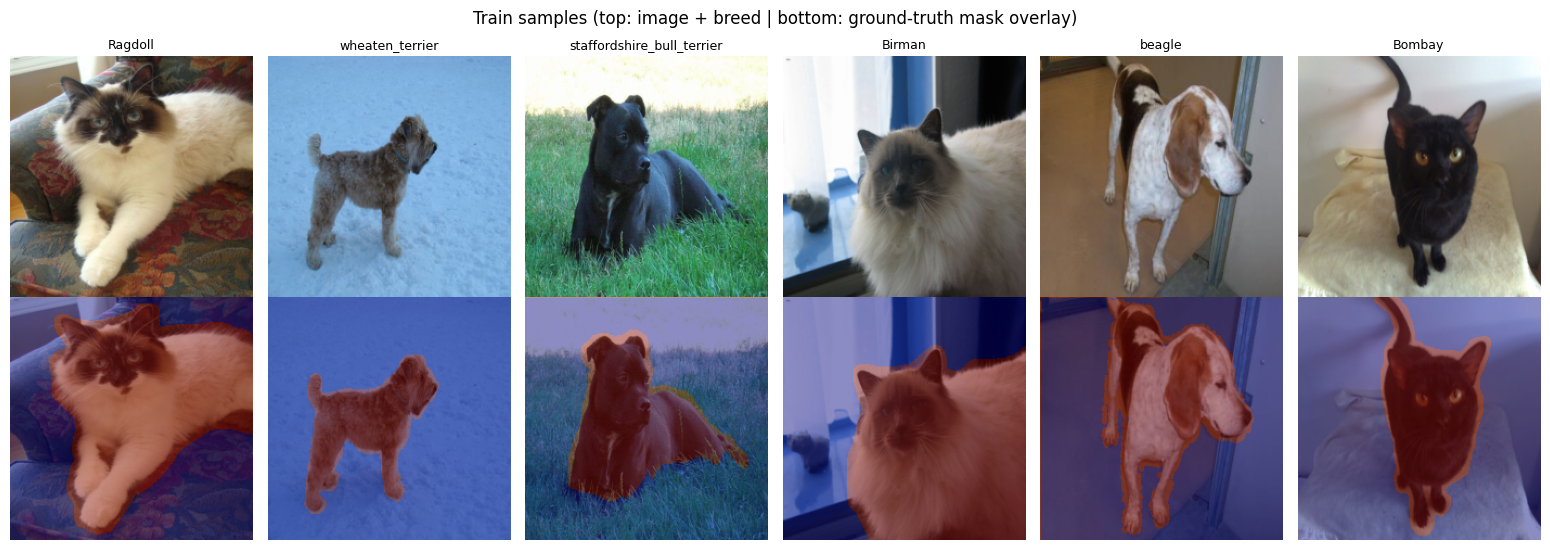

In [5]:
def denorm(x):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std  = torch.tensor(STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)

def show_samples(ds, n=6, title="samples"):
    idxs = np.random.choice(len(ds), n, replace=False)
    fig, axes = plt.subplots(2, n, figsize=(2.6 * n, 5.6))
    for j, i in enumerate(idxs):
        x, y_s, y_c = ds[int(i)]
        img = denorm(x).permute(1, 2, 0).numpy()
        axes[0, j].imshow(img)
        axes[0, j].set_title(CLASS_NAMES[int(y_c)], fontsize=9)
        axes[1, j].imshow(img)
        axes[1, j].imshow(y_s, cmap="jet", alpha=0.45)
    for ax in axes.ravel():
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(train_ds, n=6, title="Train samples (top: image + breed | bottom: ground-truth mask overlay)")

In [6]:
class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel attention (Hu et al., 2018)."""

    def __init__(self, ch, r=16):
        super().__init__()
        h = max(ch // r, 8)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(ch, h), nn.ReLU(inplace=True),
            nn.Linear(h, ch), nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(x)[..., None, None]


class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
        )
        self.se = SEBlock(cout)   # channel attention on every block

    def forward(self, x):
        return self.se(self.net(x))


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018, https://arxiv.org/abs/1804.03999).

    The coarse decoder signal g gates the skip features x: a per-pixel sigmoid
    coefficient suppresses background responses so only spatially relevant
    skip activations reach the decoder."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1, bias=False), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1, bias=False), nn.BatchNorm2d(f_int))
        self.psi  = nn.Sequential(nn.Conv2d(f_int, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, g):
        a = self.psi(self.relu(self.W_g(g) + self.W_x(x)))
        return x * a


class AttUNetMultiTask(nn.Module):
    """Attention U-Net (Oktay et al., 2018, https://arxiv.org/abs/1804.03999).
    Same U-Net backbone, but an additive Attention Gate now filters every one
    of the 4 skip connections. A classification head is attached to the encoder
    output (bottleneck); both heads are trained together.

    Seg->Cls skip: decoder features are pooled TWICE for classification -
    (a) globally, and (b) gated by the predicted pet-mask probability
    ('segmentation-guided attention', i.e. masked average pooling).
    This routes fine spatial detail around the lossy bottleneck."""

    def __init__(self, n_cls=37, n_seg=2, base=64, cls_dropout=0.5):
        super().__init__()
        b = base
        self.enc1 = DoubleConv(3, b)
        self.enc2 = DoubleConv(b, b * 2)
        self.enc3 = DoubleConv(b * 2, b * 4)
        self.enc4 = DoubleConv(b * 4, b * 8)
        self.bottleneck = DoubleConv(b * 8, b * 16)
        self.pool = nn.MaxPool2d(2)
        # Attention Gates on all 4 skip connections (arXiv:1804.03999)
        self.att4 = AttentionGate(b * 8, b * 8, b * 4)
        self.att3 = AttentionGate(b * 4, b * 4, b * 2)
        self.att2 = AttentionGate(b * 2, b * 2, b)
        self.att1 = AttentionGate(b, b, b // 2)

        self.up4  = nn.ConvTranspose2d(b * 16, b * 8, 2, stride=2)
        self.dec4 = DoubleConv(b * 16, b * 8)
        self.up3  = nn.ConvTranspose2d(b * 8, b * 4, 2, stride=2)
        self.dec3 = DoubleConv(b * 8, b * 4)
        self.up2  = nn.ConvTranspose2d(b * 4, b * 2, 2, stride=2)
        self.dec2 = DoubleConv(b * 4, b * 2)
        self.up1  = nn.ConvTranspose2d(b * 2, b, 2, stride=2)
        self.dec1 = DoubleConv(b * 2, b)

        self.seg_head = nn.Conv2d(b, n_seg, kernel_size=1)

        self.gap = nn.AdaptiveAvgPool2d(1)
        self.gmp = nn.AdaptiveMaxPool2d(1)
        self.cls_head = nn.Sequential(              # deeper head: hidden layer helps fine-grained splits
            nn.Dropout(cls_dropout),
            nn.Linear(b * 16 * 2 + b * 2, 512),     # [GAP+GMP bottleneck | decoder-global | pet-masked]
            nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Dropout(cls_dropout * 0.5),
            nn.Linear(512, n_cls),
        )

    @staticmethod
    def _pad_to_match(x, skip):
        dh = skip.shape[2] - x.shape[2]
        dw = skip.shape[3] - x.shape[3]
        return F.pad(x, [dw // 2, dw - dw // 2, dh // 2, dh - dh // 2])

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        bn = self.bottleneck(self.pool(e4))

        g4 = self._pad_to_match(self.up4(bn), e4)
        d = self.dec4(torch.cat([g4, self.att4(e4, g4)], dim=1))
        g3 = self._pad_to_match(self.up3(d), e3)
        d = self.dec3(torch.cat([g3, self.att3(e3, g3)], dim=1))
        g2 = self._pad_to_match(self.up2(d), e2)
        d = self.dec2(torch.cat([g2, self.att2(e2, g2)], dim=1))
        g1 = self._pad_to_match(self.up1(d), e1)
        d = self.dec1(torch.cat([g1, self.att1(e1, g1)], dim=1))

        seg_logits = self.seg_head(d)              # full-resolution segmentation

        # --- seg -> cls skip: segmentation-guided pooling ---
        bn_vec = torch.cat([self.gap(bn).flatten(1), self.gmp(bn).flatten(1)], dim=1)  # avg+max context
        d_vec  = F.adaptive_avg_pool2d(d, 1).flatten(1)      # decoder context  (64)
        pet_p  = torch.softmax(seg_logits, dim=1)[:, 1:2]    # predicted P(pet) per pixel
        fg_vec = (d * pet_p).sum(dim=(2, 3)) / (pet_p.sum(dim=(2, 3)) + 1e-6)
        cls_logits = self.cls_head(torch.cat([bn_vec, d_vec, fg_vec], dim=1))
        return cls_logits, seg_logits


model = AttUNetMultiTask(CFG.NUM_CLASSES, SEG_CLASSES, CFG.BASE_CH, CFG.CLS_DROPOUT).to(DEVICE)
print(f"{model.__class__.__name__} | params: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")
print(model)
model.eval()
with torch.no_grad():
    lc, ls = model(torch.randn(2, 3, CFG.IMG_SIZE, CFG.IMG_SIZE, device=DEVICE))
print("sanity check -> cls_logits:", tuple(lc.shape), "| seg_logits:", tuple(ls.shape))

AttUNetMultiTask | params: 50.80M
AttUNetMultiTask(
  (enc1): DoubleConv(
    (net): Sequential(
      (0): Conv2d(3, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(80, 80, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(80, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (se): SEBlock(
      (fc): Sequential(
        (0): AdaptiveAvgPool2d(output_size=1)
        (1): Flatten(start_dim=1, end_dim=-1)
        (2): Linear(in_features=80, out_features=8, bias=True)
        (3): ReLU(inplace=True)
        (4): Linear(in_features=8, out_features=80, bias=True)
        (5): Sigmoid()
      )
    )
  )
  (enc2): DoubleConv(
    (net): Sequential(
      (0): Conv2d(80, 160, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1)

In [7]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1.0):
        super().__init__()
        self.eps = eps

    def forward(self, logits, target):
        n_cls  = logits.shape[1]
        probs  = F.softmax(logits, dim=1)
        onehot = F.one_hot(target.clamp(0, n_cls - 1), n_cls).permute(0, 3, 1, 2).float()
        dims   = (0, 2, 3)
        inter  = (probs * onehot).sum(dim=dims)
        card   = probs.sum(dim=dims) + onehot.sum(dim=dims)
        dice   = (2.0 * inter + self.eps) / (card + self.eps)
        return 1.0 - dice.mean()


CE_CLS = nn.CrossEntropyLoss(label_smoothing=CFG.LABEL_SMOOTH)
CE_SEG = nn.CrossEntropyLoss()
DICE   = DiceLoss()

def maybe_mixup(x):
    """Optionally MixUp the batch. Returns (x_mixed, lam, idx) with lam=None when not mixed."""
    if CFG.MIXUP_ALPHA <= 0 or random.random() >= CFG.MIXUP_PROB:
        return x, None, None
    lam = float(np.random.beta(CFG.MIXUP_ALPHA, CFG.MIXUP_ALPHA))
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], lam, idx


def criterion(cls_logits, seg_logits, y_c, y_s, mix=None):
    # MixUp helps classification but hurts segmentation (blended masks are nonsensical).
    # Apply mixup ONLY to the classification loss; segmentation always uses clean inputs.
    if mix is None:
        loss_cls = CE_CLS(cls_logits, y_c)
    else:
        lam, idx = mix
        loss_cls = lam * CE_CLS(cls_logits, y_c) + (1 - lam) * CE_CLS(cls_logits, y_c[idx])
    loss_seg = CE_SEG(seg_logits, y_s) + DICE(seg_logits, y_s)
    return loss_cls + loss_seg, loss_cls.detach(), loss_seg.detach()


OPTIMIZER = torch.optim.AdamW(model.parameters(), lr=CFG.LR, weight_decay=CFG.WEIGHT_DECAY)
SCHEDULER = torch.optim.lr_scheduler.CosineAnnealingLR(OPTIMIZER, T_max=CFG.EPOCHS)
SCALER    = torch.cuda.amp.GradScaler(enabled=USE_AMP)
print("Joint objective:  L = CE(classification) + [CE(segmentation) + DiceLoss]")


class ModelEMA:
    """Exponential moving average of weights - the EMA copy usually generalizes better."""

    def __init__(self, net, decay=0.999):
        self.ema, self.decay = copy.deepcopy(net).eval(), decay
        for p in self.ema.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, net):
        msd = net.state_dict()
        for k, v in self.ema.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(self.decay).add_(msd[k].detach(), alpha=1 - self.decay)
            else:
                v.copy_(msd[k])


EMA = ModelEMA(model, decay=0.999) if DEVICE.type == "cuda" else None
print("EMA weight averaging:", "ON (decay 0.999)" if EMA else "off (cpu)")

Joint objective:  L = CE(classification) + [CE(segmentation) + DiceLoss]
EMA weight averaging: ON (decay 0.999)


In [8]:
class SegMetrics:
    """Confusion-matrix based segmentation metrics: mIoU, Dice, pixel accuracy."""

    def __init__(self, n_classes, class_names):
        self.n = n_classes
        self.names = class_names
        self.reset()

    def reset(self):
        self.cm = np.zeros((self.n, self.n), dtype=np.int64)

    @torch.no_grad()
    def update(self, pred, target):
        p = pred.detach().cpu().numpy().reshape(-1)
        t = target.detach().cpu().numpy().reshape(-1)
        idx = t * self.n + p
        self.cm += np.bincount(idx, minlength=self.n * self.n).reshape(self.n, self.n)

    def results(self):
        cm = self.cm.astype(np.float64)
        tp = np.diag(cm)
        fp = cm.sum(axis=0) - tp
        fn = cm.sum(axis=1) - tp
        iou  = np.divide(tp, tp + fp + fn, out=np.zeros_like(tp), where=(tp + fp + fn) > 0)
        dice = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros_like(tp), where=(2 * tp + fp + fn) > 0)
        pix_acc = tp.sum() / max(cm.sum(), 1)
        per_class = {name: {"IoU": float(iou[i]), "Dice": float(dice[i])}
                     for i, name in enumerate(self.names)}
        return {"mIoU": float(iou.mean()), "Dice": float(dice.mean()),
                "PixelAccuracy": float(pix_acc), "per_class": per_class}


def classification_metrics(y_true, y_pred):
    return {
        "Accuracy":  float(accuracy_score(y_true, y_pred)),
        "Precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "Recall":    float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "F1":        float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
    }

In [9]:
def run_epoch(net, loader, optimizer=None, desc=""):
    train_mode = optimizer is not None
    net.train() if train_mode else net.eval()
    seg_m = SegMetrics(SEG_CLASSES, SEG_CLASS_NAMES)
    ys_all, yp_all = [], []
    tot = {"loss": 0.0, "cls": 0.0, "seg": 0.0}
    nb = 0
    grad_ctx = torch.enable_grad() if train_mode else torch.no_grad()

    for x, y_s, y_c in tqdm(loader, desc=desc, leave=False):
        x   = x.to(DEVICE, non_blocking=True)
        y_s = y_s.to(DEVICE, non_blocking=True)
        y_c = y_c.to(DEVICE, non_blocking=True)

        mix = None
        x_clean = x
        if train_mode:
            x_mixed, lam, idx = maybe_mixup(x)
            if lam is not None:
                mix = (lam, idx)
                x = x_mixed

        with grad_ctx, torch.cuda.amp.autocast(enabled=USE_AMP):
            if train_mode or not CFG.USE_TTA:
                if mix is not None:
                    # Two passes: mixed image for cls, clean image for seg
                    cls_logits, _ = net(x)
                    _, seg_logits = net(x_clean)
                else:
                    cls_logits, seg_logits = net(x)
                loss, loss_cls, loss_seg = criterion(cls_logits, seg_logits, y_c, y_s, mix)
            else:
                # eval-time TTA: horizontal flip + 1.15x multi-scale, logits averaged
                cls_a, seg_a = net(x)
                cls_b, seg_b = net(torch.flip(x, dims=[3]))
                cls_c, seg_c = net(F.interpolate(x, scale_factor=1.15, mode="bilinear", align_corners=False))
                seg_c = F.interpolate(seg_c, size=seg_a.shape[2:], mode="bilinear", align_corners=False)
                cls_logits = (cls_a + cls_b + cls_c) / 3.0
                seg_logits = (seg_a + seg_b + seg_c) / 3.0
                loss, loss_cls, loss_seg = criterion(cls_logits, seg_logits, y_c, y_s)

        if train_mode:
            optimizer.zero_grad(set_to_none=True)
            SCALER.scale(loss).backward()
            SCALER.step(optimizer)
            SCALER.update()
            if EMA is not None:
                EMA.update(net)

        nb += 1
        tot["loss"] += loss.item()
        tot["cls"]  += float(loss_cls)
        tot["seg"]  += float(loss_seg)
        seg_m.update(seg_logits.argmax(1), y_s)
        ys_all.append(y_c.cpu())
        yp_all.append(cls_logits.argmax(1).cpu())

    seg_res = seg_m.results()
    cls_res = classification_metrics(torch.cat(ys_all).numpy(), torch.cat(yp_all).numpy())
    return {k: v / max(nb, 1) for k, v in tot.items()}, seg_res, cls_res


def evaluate_split(net, loader, tag):
    losses, seg_res, cls_res = run_epoch(net, loader, None, f"[{tag}]")
    return {"losses": losses, "seg": seg_res, "cls": cls_res}

print("helpers ready")

helpers ready


In [10]:
history = {"train_loss": [], "val_loss": [], "val_mIoU": [], "val_Dice": [],
           "val_Accuracy": [], "val_F1": [], "lr": []}
best_val_miou = -1.0
best_state    = copy.deepcopy(model.state_dict())
best_src      = "model"
bad_epochs    = 0
t_start       = time.time()

for epoch in range(1, CFG.EPOCHS + 1):
    tr_loss, _, _ = run_epoch(model, LOADERS["train"], OPTIMIZER, f"epoch {epoch:02d} [train]")
    SCHEDULER.step()

    val   = evaluate_split(model, LOADERS["val"], "val")
    val_e = evaluate_split(EMA.ema, LOADERS["val"], "val-ema") if EMA is not None else None
    history["train_loss"].append(tr_loss["loss"])
    history["val_loss"].append(val["losses"]["loss"])
    history["val_mIoU"].append(val["seg"]["mIoU"])
    history["val_Dice"].append(val["seg"]["Dice"])
    history["val_Accuracy"].append(val["cls"]["Accuracy"])
    history["val_F1"].append(val["cls"]["F1"])
    history["lr"].append(OPTIMIZER.param_groups[0]["lr"])

    ema_txt = ""
    if val_e is not None:
        ema_txt = f" | ema_mIoU {val_e['seg']['mIoU']:.4f} | ema_acc {val_e['cls']['Accuracy']:.4f}"
    print(f"epoch {epoch:03d} | train_loss {tr_loss['loss']:.4f} | val_loss {val['losses']['loss']:.4f}"
          f" | mIoU {val['seg']['mIoU']:.4f} | Dice {val['seg']['Dice']:.4f}"
          f" | pixAcc {val['seg']['PixelAccuracy']:.4f}"
          f" | acc {val['cls']['Accuracy']:.4f} | F1 {val['cls']['F1']:.4f}" + ema_txt)

    # keep the best of {raw model, EMA} by val mIoU
    candidates = [("model", val["seg"]["mIoU"], copy.deepcopy(model.state_dict()))]
    if val_e is not None:
        candidates.append(("ema", val_e["seg"]["mIoU"], copy.deepcopy(EMA.ema.state_dict())))
    src, score, state = max(candidates, key=lambda t: t[1])

    if score > best_val_miou + 1e-5:
        best_val_miou, best_state, best_src, bad_epochs = score, state, src, 0
        torch.save(best_state, OUT_DIR / "best_attunet_multitask.pt")
    else:
        bad_epochs += 1
        if bad_epochs >= CFG.PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val mIoU gain for {CFG.PATIENCE} epochs).")
            break

model.load_state_dict(best_state)
print(f"training done in {(time.time() - t_start) / 60:.1f} min | best val mIoU = {best_val_miou:.4f} (from: {best_src})")

epoch 001 | train_loss 4.4162 | val_loss 4.2433 | mIoU 0.6720 | Dice 0.8036 | pixAcc 0.8052 | acc 0.0453 | F1 0.0088 | ema_mIoU 0.2988 | ema_acc 0.0272


epoch 002 | train_loss 4.0698 | val_loss 3.9774 | mIoU 0.7240 | Dice 0.8392 | pixAcc 0.8447 | acc 0.0942 | F1 0.0490 | ema_mIoU 0.2988 | ema_acc 0.0272


epoch 003 | train_loss 3.7422 | val_loss 3.8383 | mIoU 0.7167 | Dice 0.8332 | pixAcc 0.8455 | acc 0.1250 | F1 0.0842 | ema_mIoU 0.2988 | ema_acc 0.0272


epoch 004 | train_loss 3.4484 | val_loss 3.7732 | mIoU 0.7650 | Dice 0.8662 | pixAcc 0.8711 | acc 0.1504 | F1 0.1272 | ema_mIoU 0.2988 | ema_acc 0.0254


epoch 005 | train_loss 3.1882 | val_loss 3.3192 | mIoU 0.7609 | Dice 0.8631 | pixAcc 0.8728 | acc 0.2373 | F1 0.2060 | ema_mIoU 0.2988 | ema_acc 0.0254


epoch 006 | train_loss 3.0105 | val_loss 3.2648 | mIoU 0.7860 | Dice 0.8799 | pixAcc 0.8826 | acc 0.2428 | F1 0.2187 | ema_mIoU 0.2988 | ema_acc 0.0254


... (42 outputs left out)

epoch 049 | train_loss 0.8276 | val_loss 1.7542 | mIoU 0.8902 | Dice 0.9418 | pixAcc 0.9440 | acc 0.7409 | F1 0.7372 | ema_mIoU 0.8935 | ema_acc 0.7373


epoch 050 | train_loss 0.8213 | val_loss 1.7637 | mIoU 0.8896 | Dice 0.9415 | pixAcc 0.9437 | acc 0.7264 | F1 0.7221 | ema_mIoU 0.8932 | ema_acc 0.7373


epoch 051 | train_loss 0.8188 | val_loss 1.7660 | mIoU 0.8901 | Dice 0.9418 | pixAcc 0.9440 | acc 0.7319 | F1 0.7282 | ema_mIoU 0.8929 | ema_acc 0.7373


epoch 052 | train_loss 0.8204 | val_loss 1.7677 | mIoU 0.8896 | Dice 0.9415 | pixAcc 0.9437 | acc 0.7246 | F1 0.7188 | ema_mIoU 0.8926 | ema_acc 0.7391
Early stopping at epoch 52 (no val mIoU gain for 10 epochs).
training done in 157.3 min | best val mIoU = 0.8947 (from: ema)


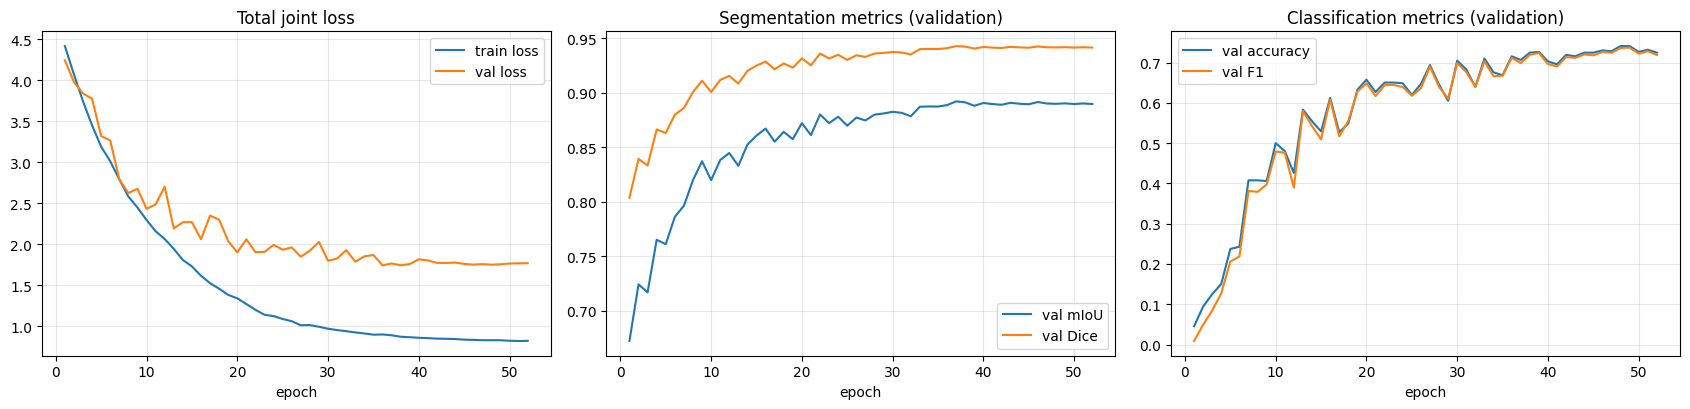

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
ep = np.arange(1, len(history["train_loss"]) + 1)

axes[0].plot(ep, history["train_loss"], label="train loss")
axes[0].plot(ep, history["val_loss"], label="val loss")
axes[0].set_title("Total joint loss"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep, history["val_mIoU"], label="val mIoU")
axes[1].plot(ep, history["val_Dice"], label="val Dice")
axes[1].set_title("Segmentation metrics (validation)")
axes[1].set_xlabel("epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(ep, history["val_Accuracy"], label="val accuracy")
axes[2].plot(ep, history["val_F1"], label="val F1")
axes[2].set_title("Classification metrics (validation)")
axes[2].set_xlabel("epoch"); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

## Result Summary — all sets (train / validation / test)
- **Segmentation:** mean Intersection over Union (mIoU), Dice coefficient, pixel accuracy
- **Classification:** accuracy, precision, recall, F1 score

In [12]:
RESULTS = {}
for tag, loader in [("Train", LOADERS["train_eval"]),
                    ("Validation", LOADERS["val"]),
                    ("Test", LOADERS["test"])]:
    RESULTS[tag] = evaluate_split(model, loader, tag)

metric_rows = ["mIoU", "Dice Coefficient", "Pixel Accuracy",
               "Accuracy", "Precision", "Recall", "F1 Score"]
summary = pd.DataFrame(index=metric_rows, columns=["Train", "Validation", "Test"], dtype=float)
for tag, res in RESULTS.items():
    summary.loc["mIoU", tag]             = res["seg"]["mIoU"]
    summary.loc["Dice Coefficient", tag] = res["seg"]["Dice"]
    summary.loc["Pixel Accuracy", tag]   = res["seg"]["PixelAccuracy"]
    summary.loc["Accuracy", tag]         = res["cls"]["Accuracy"]
    summary.loc["Precision", tag]        = res["cls"]["Precision"]
    summary.loc["Recall", tag]           = res["cls"]["Recall"]
    summary.loc["F1 Score", tag]         = res["cls"]["F1"]

print("=== RESULT SUMMARY (segmentation + classification) ===")
display(summary.round(4))
summary.round(6).to_csv(OUT_DIR / "attunet_results_summary.csv")

for tag, res in RESULTS.items():
    print(f"\nPer-class segmentation metrics [{tag}]")
    for cname, m in res["seg"]["per_class"].items():
        print(f"  {cname:<12} IoU = {m['IoU']:.4f}   Dice = {m['Dice']:.4f}")

=== RESULT SUMMARY (segmentation + classification) ===


,Train,Validation,Test
mIoU,0.9522,0.8947,0.8950
Dice Coefficient,0.9755,0.9443,0.9445
Pixel Accuracy,0.9762,0.9463,0.9459
Accuracy,1.0000,0.7337,0.7013
Precision,1.0000,0.7468,0.7073
Recall,1.0000,0.7344,0.7011
F1 Score,1.0000,0.7292,0.6984



Per-class segmentation metrics [Train]
  background   IoU = 0.9601   Dice = 0.9796
  pet          IoU = 0.9444   Dice = 0.9714

Per-class segmentation metrics [Validation]
  background   IoU = 0.9138   Dice = 0.9549
  pet          IoU = 0.8756   Dice = 0.9337

Per-class segmentation metrics [Test]
  background   IoU = 0.9107   Dice = 0.9533
  pet          IoU = 0.8793   Dice = 0.9358


In [13]:
test_preds, test_gts = [], []
model.eval()
with torch.no_grad():
    for x, _, y_c in LOADERS["test"]:
        lc, _ = model(x.to(DEVICE))
        test_preds.append(lc.argmax(1).cpu())
        test_gts.append(y_c)
test_preds = torch.cat(test_preds).numpy()
test_gts   = torch.cat(test_gts).numpy()

print("Per-breed classification report (TEST set):")
print(classification_report(test_gts, test_preds, labels=list(range(CFG.NUM_CLASSES)),
                            target_names=CLASS_NAMES, digits=4, zero_division=0))

Per-breed classification report (TEST set):
                            precision    recall  f1-score   support

                Abyssinian     0.5455    0.7959    0.6473        98
          american_bulldog     0.5455    0.7200    0.6207       100
 american_pit_bull_terrier     0.4677    0.2900    0.3580       100
              basset_hound     0.7234    0.6800    0.7010       100
                    beagle     0.6739    0.6200    0.6458       100
                    Bengal     0.5984    0.7300    0.6577       100
                    Birman     0.7222    0.6500    0.6842       100
                    Bombay     0.7292    0.7955    0.7609        88
                     boxer     0.6562    0.6364    0.6462        99
         British_Shorthair     0.6566    0.6500    0.6533       100
                 chihuahua     0.7377    0.4500    0.5590       100
              Egyptian_Mau     0.7636    0.8660    0.8116        97
    english_cocker_spaniel     0.5795    0.5100    0.5426       100
   

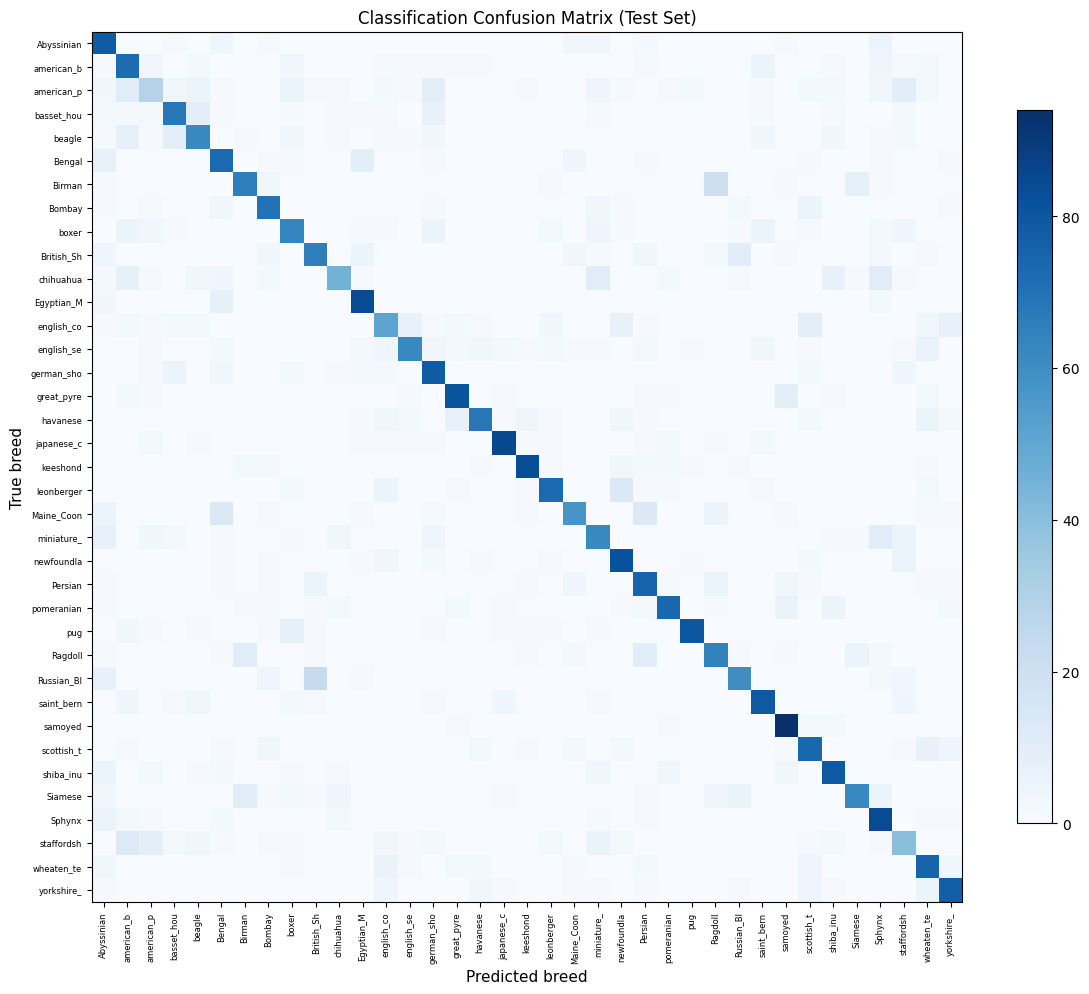

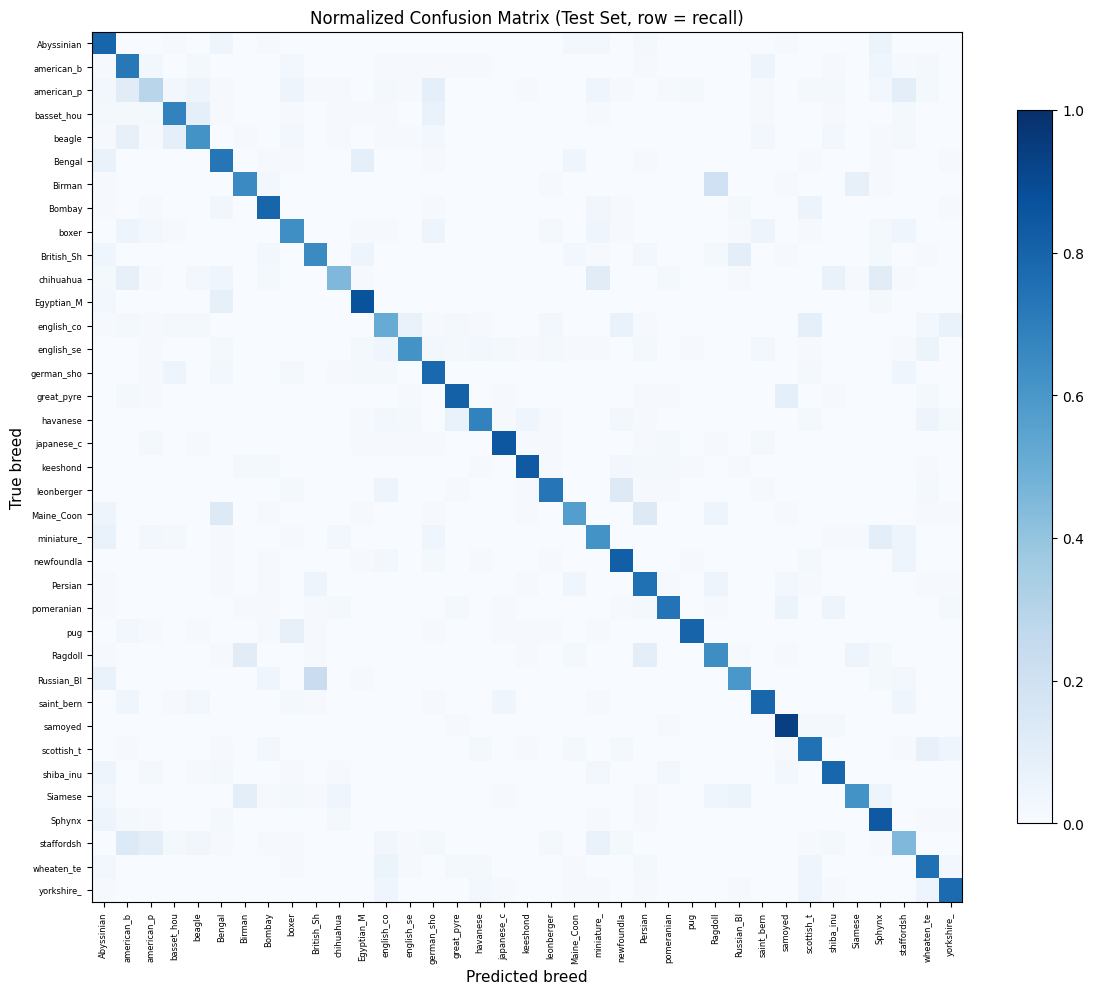

In [14]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_gts, test_preds)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap="Blues")
ax.set_xlabel("Predicted breed", fontsize=11)
ax.set_ylabel("True breed", fontsize=11)
ax.set_title("Classification Confusion Matrix (Test Set)")
plt.colorbar(im, shrink=0.8)
short = [n[:10] for n in CLASS_NAMES]
ax.set_xticks(range(CFG.NUM_CLASSES)); ax.set_xticklabels(short, rotation=90, fontsize=6)
ax.set_yticks(range(CFG.NUM_CLASSES)); ax.set_yticklabels(short, fontsize=6)
plt.tight_layout(); plt.show()

# normalized confusion matrix (row-normalized = recall per class)
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig2, ax2 = plt.subplots(figsize=(12, 10))
im2 = ax2.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax2.set_xlabel("Predicted breed", fontsize=11)
ax2.set_ylabel("True breed", fontsize=11)
ax2.set_title("Normalized Confusion Matrix (Test Set, row = recall)")
plt.colorbar(im2, shrink=0.8)
ax2.set_xticks(range(CFG.NUM_CLASSES)); ax2.set_xticklabels(short, rotation=90, fontsize=6)
ax2.set_yticks(range(CFG.NUM_CLASSES)); ax2.set_yticklabels(short, fontsize=6)
plt.tight_layout(); plt.show()

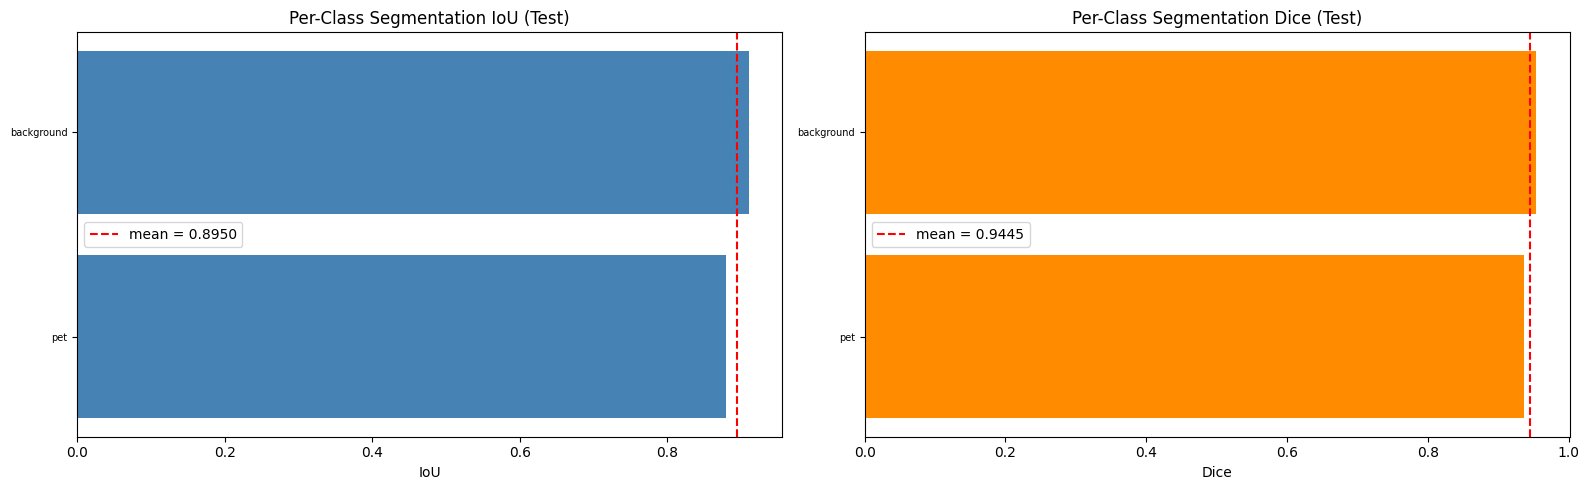

In [15]:
per_class = RESULTS["Test"]["seg"]["per_class"]
names  = list(per_class.keys())
ious   = [per_class[n]["IoU"] for n in names]
dices  = [per_class[n]["Dice"] for n in names]
idx_sorted = np.argsort(ious)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(range(len(names)), [ious[i] for i in idx_sorted], color="steelblue")
axes[0].set_yticks(range(len(names)))
axes[0].set_yticklabels([names[i] for i in idx_sorted], fontsize=7)
axes[0].set_xlabel("IoU")
axes[0].set_title("Per-Class Segmentation IoU (Test)")
axes[0].axvline(np.mean(ious), color="red", linestyle="--", label=f"mean = {np.mean(ious):.4f}")
axes[0].legend()

axes[1].barh(range(len(names)), [dices[i] for i in idx_sorted], color="darkorange")
axes[1].set_yticks(range(len(names)))
axes[1].set_yticklabels([names[i] for i in idx_sorted], fontsize=7)
axes[1].set_xlabel("Dice")
axes[1].set_title("Per-Class Segmentation Dice (Test)")
axes[1].axvline(np.mean(dices), color="red", linestyle="--", label=f"mean = {np.mean(dices):.4f}")
axes[1].legend()

plt.tight_layout(); plt.show()

## Prediction Viewer
Takes **any image index**, passes it through the model and displays
`[original image] [image + true overlay] [image + predicted mask overlay]`,
plus `original class -`, `predict class -`, `iou -`.

Call `show_prediction(<any index>)` yourself, or use the random examples below.

Presentation examples (random test indices):


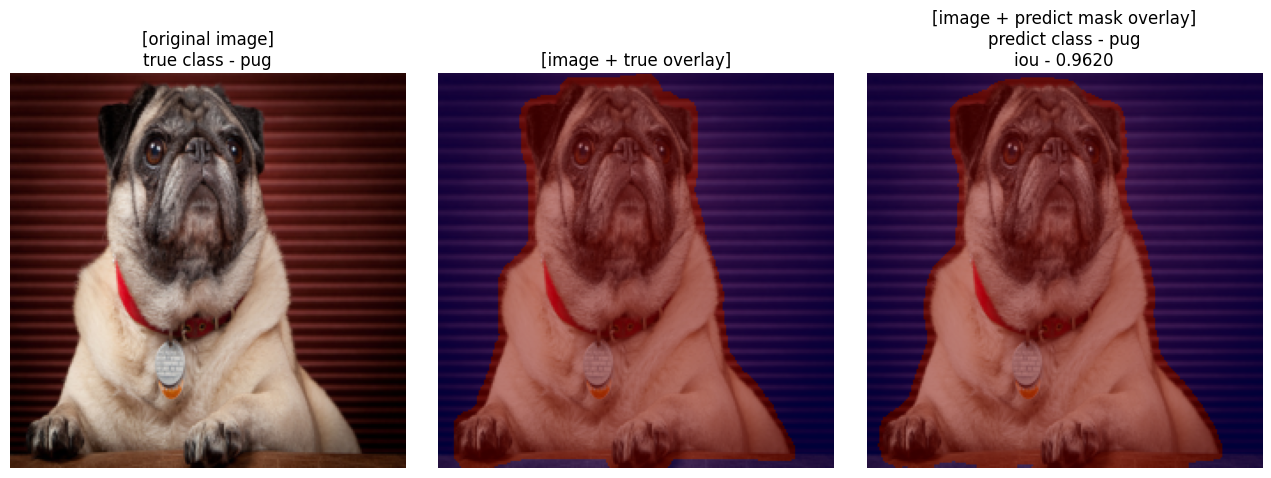

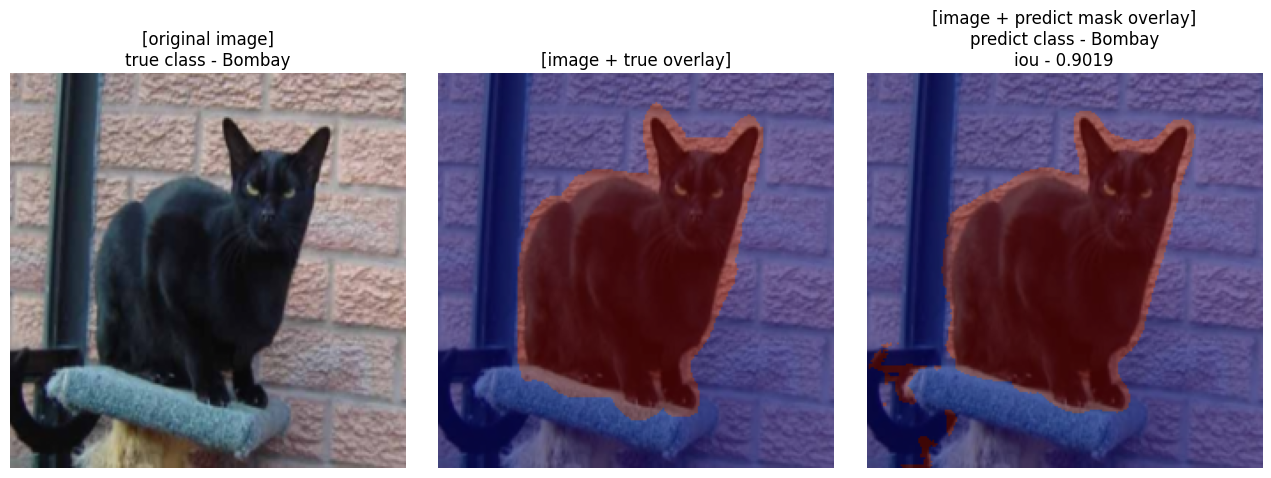

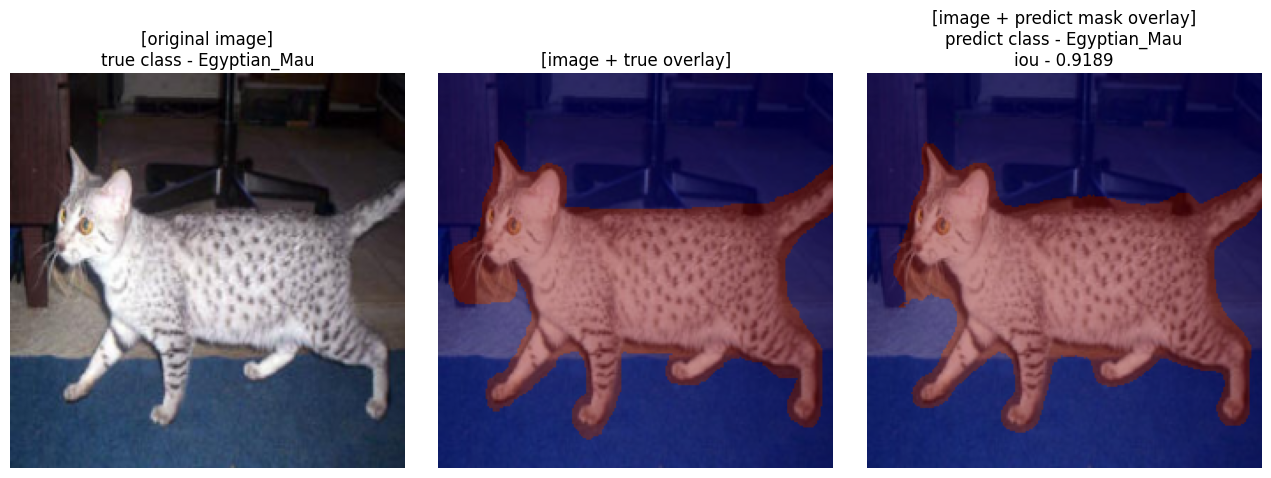

In [16]:
@torch.no_grad()
def show_prediction(idx, ds=None):
    ds = test_ds if ds is None else ds
    was_training = model.training
    model.eval()

    x, y_s, y_c = ds[int(idx)]
    lc, ls = model(x.unsqueeze(0).to(DEVICE))
    pred_c = int(lc.argmax(1).item())
    pred_s = ls.argmax(1)[0].cpu()

    gt_mask = y_s.numpy()
    pr_mask = pred_s.numpy()
    inter   = np.logical_and(gt_mask == 1, pr_mask == 1).sum()
    union   = np.logical_or(gt_mask == 1, pr_mask == 1).sum()
    iou     = float(inter) / float(union) if union > 0 else 0.0

    orig_name = CLASS_NAMES[int(y_c)]
    pred_name = CLASS_NAMES[pred_c]

    img = denorm(x).permute(1, 2, 0).numpy()
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
    axes[0].imshow(img)
    axes[0].set_title(f"[original image]\ntrue class - {orig_name}")
    axes[1].imshow(img); axes[1].imshow(gt_mask, cmap="jet", alpha=0.45)
    axes[1].set_title("[image + true overlay]")
    axes[2].imshow(img); axes[2].imshow(pr_mask, cmap="jet", alpha=0.45)
    axes[2].set_title(f"[image + predict mask overlay]\npredict class - {pred_name}\niou - {iou:.4f}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    if was_training:
        model.train()
    return {"index": int(idx), "original_class": orig_name,
            "predict_class": pred_name, "iou": iou}


print("Presentation examples (random test indices):")
for idx in np.random.choice(len(test_ds), size=3, replace=False):
    show_prediction(idx)

In [17]:
torch.save({"state_dict": model.state_dict(),
            "config": {"img_size": CFG.IMG_SIZE, "n_cls": CFG.NUM_CLASSES,
                       "n_seg": SEG_CLASSES, "base_ch": CFG.BASE_CH,
                       "cls_dropout": CFG.CLS_DROPOUT},
            "class_names": CLASS_NAMES,
            "binary_seg": bool(CFG.BINARY_SEG)},
           OUT_DIR / "attunet_multitask_final.pt")
summary.round(6).to_csv(OUT_DIR / "attunet_results_summary.csv")
print("saved ->", OUT_DIR / "attunet_multitask_final.pt")
print("saved ->", OUT_DIR / "attunet_results_summary.csv")

saved -> /kaggle/working/attunet_multitask_final.pt
saved -> /kaggle/working/attunet_results_summary.csv


## Reload & Predict Anywhere (works after the session dies)
Everything needed to predict lives inside `attunet_multitask_final.pt` (weights + architecture config + breed names).

**Fresh-session usage:**
1. This notebook's `/kaggle/working` files become its saved **Output** (also kept via *Save Version*).
2. In a NEW Kaggle notebook: **Add Input → Your Work / Datasets** → attach this output (or upload the `.pt` as a Dataset).
3. Point `CKPT_PATH` at it, e.g. `"/kaggle/input/<attached-output>/attunet_multitask_final.pt"`.
4. Run **only the cell below**, then call `predict_image("any_pet_photo.jpg")`.


In [18]:
# ================= STANDALONE INFERENCE (fresh-session friendly) =================
# Self-contained: model definition + weights loading + prediction, no other cells needed.

import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
import torchvision.transforms.functional as TF

CKPT_PATH = "/kaggle/working/attunet_multitask_final.pt"   # <-- change in a fresh session


class SEBlock(nn.Module):
    def __init__(self, ch, r=16):
        super().__init__()
        h = max(ch // r, 8)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(ch, h), nn.ReLU(inplace=True),
            nn.Linear(h, ch), nn.Sigmoid())

    def forward(self, x):
        return x * self.fc(x)[..., None, None]


class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.se = SEBlock(cout)

    def forward(self, x):
        return self.se(self.net(x))


class AttentionGate(nn.Module):
    """Additive attention gate (Oktay et al., 2018, https://arxiv.org/abs/1804.03999).

    The coarse decoder signal g gates the skip features x: a per-pixel sigmoid
    coefficient suppresses background responses so only spatially relevant
    skip activations reach the decoder."""
    def __init__(self, f_g, f_l, f_int):
        super().__init__()
        self.W_g = nn.Sequential(nn.Conv2d(f_g, f_int, 1, bias=False), nn.BatchNorm2d(f_int))
        self.W_x = nn.Sequential(nn.Conv2d(f_l, f_int, 1, bias=False), nn.BatchNorm2d(f_int))
        self.psi  = nn.Sequential(nn.Conv2d(f_int, 1, 1, bias=False), nn.BatchNorm2d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x, g):
        a = self.psi(self.relu(self.W_g(g) + self.W_x(x)))
        return x * a


class AttUNetMultiTask(nn.Module):
    def __init__(self, n_cls=37, n_seg=2, base=64, cls_dropout=0.5):
        super().__init__()
        b = base
        self.enc1, self.enc2 = DoubleConv(3, b), DoubleConv(b, b * 2)
        self.enc3, self.enc4 = DoubleConv(b * 2, b * 4), DoubleConv(b * 4, b * 8)
        self.bottleneck = DoubleConv(b * 8, b * 16)
        self.pool = nn.MaxPool2d(2)
        # Attention Gates on all 4 skip connections (arXiv:1804.03999)
        self.att4 = AttentionGate(b * 8, b * 8, b * 4)
        self.att3 = AttentionGate(b * 4, b * 4, b * 2)
        self.att2 = AttentionGate(b * 2, b * 2, b)
        self.att1 = AttentionGate(b, b, b // 2)
        self.up4, self.dec4 = nn.ConvTranspose2d(b * 16, b * 8, 2, 2), DoubleConv(b * 16, b * 8)
        self.up3, self.dec3 = nn.ConvTranspose2d(b * 8, b * 4, 2, 2), DoubleConv(b * 8, b * 4)
        self.up2, self.dec2 = nn.ConvTranspose2d(b * 4, b * 2, 2, 2), DoubleConv(b * 4, b * 2)
        self.up1, self.dec1 = nn.ConvTranspose2d(b * 2, b, 2, 2), DoubleConv(b * 2, b)
        self.seg_head = nn.Conv2d(b, n_seg, 1)
        self.gap, self.gmp = nn.AdaptiveAvgPool2d(1), nn.AdaptiveMaxPool2d(1)
        self.cls_head = nn.Sequential(
            nn.Dropout(cls_dropout), nn.Linear(b * 16 * 2 + b * 2, 512),
            nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Dropout(cls_dropout * 0.5), nn.Linear(512, n_cls))

    @staticmethod
    def _pad_to_match(x, skip):
        dh, dw = skip.shape[2] - x.shape[2], skip.shape[3] - x.shape[3]
        return F.pad(x, [dw // 2, dw - dw // 2, dh // 2, dh - dh // 2])

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        bn = self.bottleneck(self.pool(e4))

        g4 = self._pad_to_match(self.up4(bn), e4)
        d = self.dec4(torch.cat([g4, self.att4(e4, g4)], dim=1))
        g3 = self._pad_to_match(self.up3(d), e3)
        d = self.dec3(torch.cat([g3, self.att3(e3, g3)], dim=1))
        g2 = self._pad_to_match(self.up2(d), e2)
        d = self.dec2(torch.cat([g2, self.att2(e2, g2)], dim=1))
        g1 = self._pad_to_match(self.up1(d), e1)
        d = self.dec1(torch.cat([g1, self.att1(e1, g1)], dim=1))

        seg_logits = self.seg_head(d)
        bn_vec = torch.cat([self.gap(bn).flatten(1), self.gmp(bn).flatten(1)], dim=1)
        d_vec = F.adaptive_avg_pool2d(d, 1).flatten(1)
        pet_p = torch.softmax(seg_logits, dim=1)[:, 1:2]
        fg_vec = (d * pet_p).sum(dim=(2, 3)) / (pet_p.sum(dim=(2, 3)) + 1e-6)
        cls_logits = self.cls_head(torch.cat([bn_vec, d_vec, fg_vec], dim=1))
        return cls_logits, seg_logits


def load_pet_model(ckpt_path=CKPT_PATH):
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ckpt = torch.load(ckpt_path, map_location=dev)
    c = ckpt["config"]
    net = AttUNetMultiTask(c["n_cls"], c["n_seg"], c["base_ch"], c.get("cls_dropout", 0.5))
    net.load_state_dict(ckpt["state_dict"])
    return net.to(dev).eval(), ckpt

PET_MODEL, PET_CKPT = load_pet_model()
PET_SIZE  = PET_CKPT["config"]["img_size"]
PET_NAMES = PET_CKPT["class_names"]
_PET_MEAN = torch.tensor([0.485, 0.456, 0.406])
_PET_STD  = torch.tensor([0.229, 0.224, 0.225])
print(f"model loaded from {CKPT_PATH} | {len(PET_NAMES)} breeds | input {PET_SIZE}px")


@torch.no_grad()
def predict_image(path, tta_flip=False):  # TTA off - no-augmentation variant
    """Upload ANY cat/dog photo -> segmentation overlay + breed prediction (+ top-3)."""
    dev = next(PET_MODEL.parameters()).device
    pil = Image.open(path).convert("RGB").resize((PET_SIZE, PET_SIZE), Image.BILINEAR)
    x = TF.normalize(TF.to_tensor(pil), _PET_MEAN.tolist(), _PET_STD.tolist()).unsqueeze(0).to(dev)

    lc, ls = PET_MODEL(x)
    if tta_flip:
        lc2, ls2 = PET_MODEL(torch.flip(x, dims=[3]))
        lc, ls = 0.5 * (lc + lc2), 0.5 * (ls + ls2)

    prob = torch.softmax(lc, dim=1)[0]
    top3 = torch.argsort(prob, descending=True)[:3]
    mask = ls.argmax(1)[0].cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
    axes[0].imshow(pil); axes[0].set_title("[uploaded image]")
    axes[1].imshow(pil); axes[1].imshow(mask, cmap="jet", alpha=0.45)
    axes[1].set_title("[predicted segmentation]")
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"predict class - {PET_NAMES[top3[0]]}   ({float(prob[top3[0]]):.1%})")
    plt.tight_layout(); plt.show()

    print("Top-3 predictions:")
    for rank, i in enumerate(top3, 1):
        print(f"  {rank}. {PET_NAMES[i]:<20} {float(prob[i]):.1%}")
    print(f"Segmentation: pet covers {mask.mean() * 100:.1f}% of the image")
    return {"breed": PET_NAMES[top3[0]], "confidence": float(prob[top3[0]]),
            "top3": [(PET_NAMES[i], float(prob[i])) for i in top3], "mask": mask}

print("ready ->  predict_image('/kaggle/input/<some-photo>/cat.jpg')")

model loaded from /kaggle/working/attunet_multitask_final.pt | 37 breeds | input 224px
ready ->  predict_image('/kaggle/input/<some-photo>/cat.jpg')


In [19]:
# ============ OPTIONAL: MULTI-RUN ENSEMBLE (final accuracy push) ============
# How to use: train 2-3 runs with different CFG.SEED (same config), keep each
# run's saved Output (Add Input -> attach earlier runs), then list the
# checkpoint paths here and run this cell. Logit ensembling typically adds +1.5-3%.
ENSEMBLE_CKPTS = []   # e.g. ["/kaggle/input/run-1/attunet_multitask_final.pt",
                      #        "/kaggle/input/run-2/attunet_multitask_final.pt"]

if len(ENSEMBLE_CKPTS) >= 2:
    members = [load_pet_model(p)[0] for p in ENSEMBLE_CKPTS]
    ys, ens_preds = [], []
    for x, _, y_c in tqdm(LOADERS["test"], desc="ensemble [test]"):
        probs = None
        with torch.no_grad():
            for net_i in members:
                lc1, _ = net_i(x.to(DEVICE))
                lc2, _ = net_i(torch.flip(x.to(DEVICE), dims=[3]))
                p_i = torch.softmax(0.5 * (lc1 + lc2), dim=1).cpu()
                probs = p_i if probs is None else probs + p_i
        ens_preds.append(probs.argmax(1))
        ys.append(y_c)
    ens_m = classification_metrics(torch.cat(ys).numpy(), torch.cat(ens_preds).numpy())
    print("single model (test):", {k: round(v, 4) for k, v in RESULTS["Test"]["cls"].items()})
    print("ENSEMBLE     (test):", {k: round(v, 4) for k, v in ens_m.items()})
else:
    print("Add >= 2 checkpoint paths to ENSEMBLE_CKPTS to run the ensemble.")

Add >= 2 checkpoint paths to ENSEMBLE_CKPTS to run the ensemble.
